In [1]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
df_train = trizod_df[~trizod_df["is_test"]]
df_test = trizod_df[trizod_df["is_test"]]

In [ ]:
filename = "test7.csv"

if not os.path.exists(filename):
    fasta_filename = "test.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_test.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "adopt2g-predict",
            "--input",
            fasta_filename,
            "--out",
            filename,
            "--save-member-gscores",
            # "--ensemble-id",
            # "seed883_n5",
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_std": lambda x: np.array(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

2026-01-10 09:29:03 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed883_n7/manifest.json...
2026-01-10 09:29:03 [INFO] adopt2g.inference:   Ensemble ID: seed883_n7
2026-01-10 09:29:03 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-10 09:29:03 [INFO] adopt2g.inference:   Calibration factor: 3.3173
2026-01-10 09:29:03 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-10 09:29:04 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.warn(


2026-01-10 09:29:04 [INFO] adopt2g.inference:   Loading 7 ST models...
2026-01-10 09:29:04 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:29:04 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_0/st
2026-01-10 09:29:05 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:29:05 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_1/st
2026-01-10 09:29:05 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:29:05 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_2/st
2026-01-10 09:29:05 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:29:05 

Processing:   0%|          | 0/160 [00:00<?, ?it/s]
                                                   
Batches: 100%|██████████| 5/5 [00:00<00:00, 18.30it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 29.96it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 29.92it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 30.10it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 30.06it/s]

Batches: 100%|██████████| 5/5 [00:00<00:00, 29.84it/s]

100%|██████████| 1/1 [00:04<00:00,  4.26s/it]


2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict: Combining chunks...
2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict: Results saved to test7.csv
2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict: Columns: label, sequence, mean_gscore, mean_gscore_std, gscores, gscores_std, member_gscores
2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict:   - mean_gscore_std: calibrated std across ensemble members of per-member mean_gscore
2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict:   - gscores_std: calibrated per-residue std across ensemble members (JSON array)
2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict:   - member_gscores: per-residue gscores for each ensemble member (JSON 2D array)
2026-01-10 09:29:10 [INFO] adopt2g.scripts.predict: (Use json.loads() to parse JSON array columns)


,sequence,mean_gscore,mean_gscore_std,gscores,gscores_std,member_gscores
label,,,,,,
623_1_1_1,FKLGGRDSRSGSPMARR,0.512695,0.353778,"[0.285400390625, 0.38720703125, 0.3642578125, ...","[0.2099609375, 0.304931640625, 0.348876953125,...","[[0.39404296875, 0.51953125, 0.416748046875, 0..."
1515_1_1_1,RERIDLLWKIARAGARSAVG,0.333740,0.226916,"[0.261474609375, 0.199462890625, 0.22863769531...","[0.20361328125, 0.06988525390625, 0.1469726562...","[[0.241455078125, 0.2176513671875, 0.229858398..."
1698_1_1_1,XLYENKPRRPYIL,0.395508,0.340042,"[nan, 0.37646484375, 0.392822265625, 0.4138183...","[nan, 0.279296875, 0.322509765625, 0.316650390...","[[nan, 0.415283203125, 0.40576171875, 0.476806..."
1997_1_1_1,RYVVLPRPVCFEKGMNYTVR,0.362793,0.627396,"[0.2314453125, 0.375244140625, 0.386474609375,...","[0.277587890625, 0.6171875, 0.69140625, 0.7958...","[[0.388671875, 0.6865234375, 0.724609375, 0.73..."
3322_1_1_1,GSCWAQSQGYNCCNNPSSTKVEYTDASGQWGVQNGQWCGIDYSYGQ...,0.161255,0.063978,"[0.2275390625, 0.1568603515625, 0.16552734375,...","[0.1385498046875, 0.0718994140625, 0.070861816...","[[0.22802734375, 0.160888671875, 0.1650390625,..."
...,...,...,...,...,...,...
52503_1_1_1,MKVAVVRTPPKSPSSAKSRLQTAPVPMPDLKNVKSKIGSTENLKHQ...,0.821777,0.076873,"[0.68212890625, 0.74560546875, 0.80810546875, ...","[0.11297607421875, 0.164306640625, 0.073486328...","[[0.6416015625, 0.74951171875, 0.79443359375, ..."
52589_1_1_1,GAMGKSLSHLPLHSSKEDAYDGVTSENMRNGLVNSEVHNEDGRNGD...,0.814453,0.130712,"[0.6923828125, 0.77392578125, 0.8076171875, 0....","[0.3388671875, 0.1441650390625, 0.119812011718...","[[0.73388671875, 0.80712890625, 0.80859375, 0...."
52737_1_1_1,MPGHLQEGFGCVVTNRFDQLFDDESDPFEVLKAAENKKKEAGGGGV...,0.842285,0.081522,"[0.6416015625, 0.75537109375, 0.865234375, 0.8...","[0.37451171875, 0.1732177734375, 0.09588623046...","[[0.6884765625, 0.69189453125, 0.8828125, 0.82..."


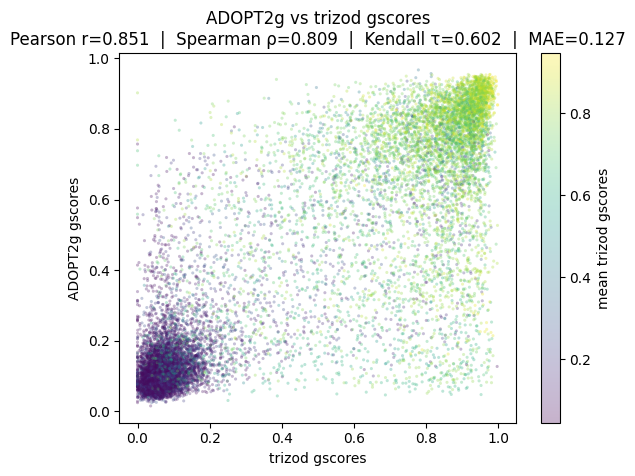

Summary of metrics for each member and mean prediction:

member_id  pearson_r  spearman_rho  kendall_tau    mae
     mean     0.8507        0.8087       0.6021 0.1268
        0     0.8398        0.8004       0.5923 0.1299
        1     0.8310        0.7870       0.5806 0.1331
        2     0.8342        0.7891       0.5817 0.1328
        3     0.8326        0.7931       0.5855 0.1326
        4     0.8347        0.7922       0.5839 0.1314
        5     0.8394        0.7965       0.5894 0.1286
        6     0.8383        0.7981       0.5891 0.1302
No members have better metrics than the mean prediction.


In [4]:
from scipy.stats import kendalltau, pearsonr, spearmanr

member_metrics = []
mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_test["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

member_metrics.append(
    {
        "member_id": "mean",
        "pearson_r": pearson_r,
        "spearman_rho": spearman_rho,
        "kendall_tau": kendall_tau,
        "mae": mae,
    }
)

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.show()

n_members = len(df_inferred["member_gscores"].iloc[0]) if "member_gscores" in df_inferred.columns else 0

# Prepare to collect summary stats for each member
for m in range(n_members):
    mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
    trizod_gscores = np.concatenate(df_test["gscores"].values)
    # Select the gscores for the current member 'm' from the 2D list in each row, then flatten
    adopt2_gscores = np.concatenate([gscores[m] for gscores in df_inferred["member_gscores"].values])
    mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

    # Compute correlation metrics
    pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
    spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
    kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

    # Also compute MAE for prediction accuracy
    mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

    member_metrics.append(
        {
            "member_id": m,
            "pearson_r": pearson_r,
            "spearman_rho": spearman_rho,
            "kendall_tau": kendall_tau,
            "mae": mae,
        }
    )

    # plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
    # plt.xlabel("trizod gscores")
    # plt.ylabel("ADOPT2g gscores")
    # plt.title(
    #     f"m={m}: ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
    # )
    # plt.colorbar(label="mean trizod gscores")
    # plt.show()

if n_members > 0:
    summary_df = pd.DataFrame(member_metrics)
    print("Summary of metrics for each member and mean prediction:\n")
    print(summary_df.to_string(index=False, float_format="%.4f"))

    # Check if any member has better metric than mean
    # Lower MAE is better, higher correlation is better
    mae_mean = summary_df["mae"][summary_df["member_id"] == "mean"].values[0]
    pearson_r_mean = summary_df["pearson_r"][summary_df["member_id"] == "mean"].values[0]
    spearman_rho_mean = summary_df["spearman_rho"][summary_df["member_id"] == "mean"].values[0]
    kendall_tau_mean = summary_df["kendall_tau"][summary_df["member_id"] == "mean"].values[0]

    better_mae_members = summary_df[summary_df["mae"] < mae_mean]["member_id"].tolist()
    better_pearson_members = summary_df[summary_df["pearson_r"] > pearson_r_mean]["member_id"].tolist()
    better_spearman_members = summary_df[summary_df["spearman_rho"] > spearman_rho_mean]["member_id"].tolist()
    better_kendall_members = summary_df[summary_df["kendall_tau"] > kendall_tau_mean]["member_id"].tolist()

    if better_mae_members or better_pearson_members or better_spearman_members or better_kendall_members:
        print("\nWARNING: Some members have better metrics than the mean prediction:")
        if better_mae_members:
            print(f"  Members with lower MAE than mean: {better_mae_members}")
        if better_pearson_members:
            print(f"  Members with higher Pearson r than mean: {better_pearson_members}")
        if better_spearman_members:
            print(f"  Members with higher Spearman rho than mean: {better_spearman_members}")
        if better_kendall_members:
            print(f"  Members with higher Kendall tau than mean: {better_kendall_members}")
    else:
        print("No members have better metrics than the mean prediction.")


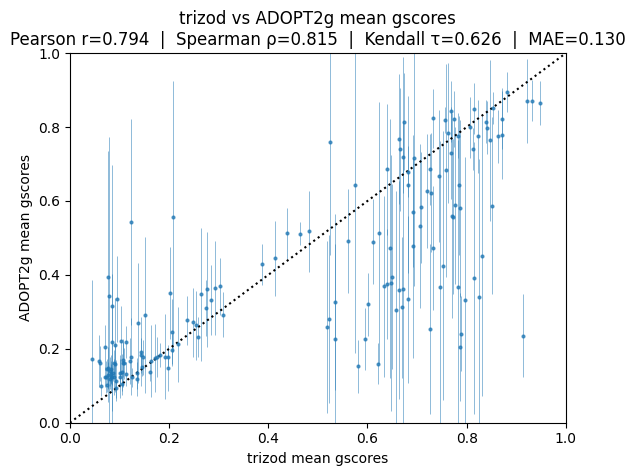

In [5]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_test["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_test["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_test["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_test["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_test["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=df_inferred["mean_gscore_std"],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


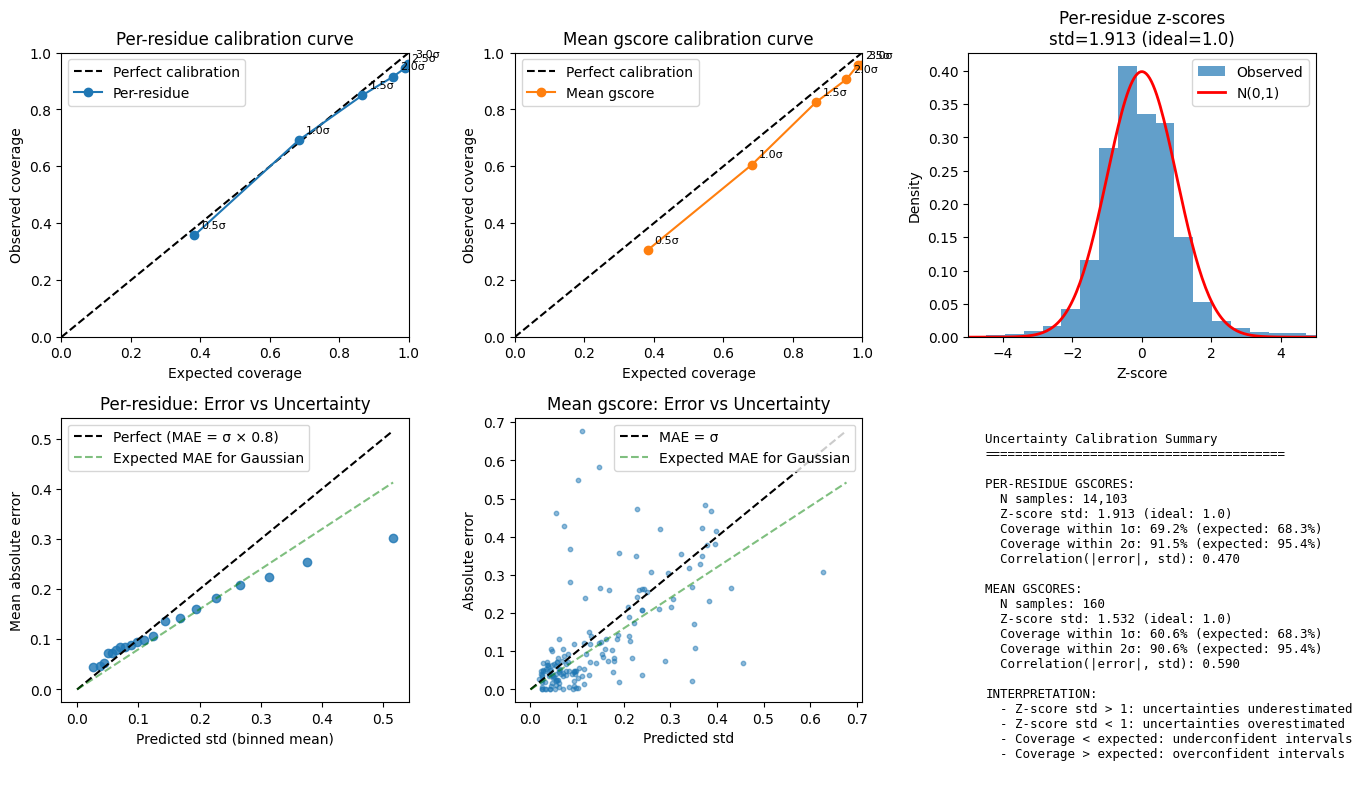

In [6]:
# Uncertainty calibration analysis
# For well-calibrated uncertainties, ~68% of true values should fall within ±1σ, ~95% within ±2σ

# --- Per-residue uncertainty calibration ---
trizod_gscores = np.concatenate(df_test["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_std = np.concatenate(df_inferred["gscores_std"].values)

# Mask for valid values
mask = np.isfinite(trizod_gscores) & np.isfinite(pred_gscores) & np.isfinite(pred_gscores_std) & (pred_gscores_std > 0)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
pred_stds = pred_gscores_std[mask]

# Compute z-scores (normalized residuals)
residuals = true_vals - pred_vals
z_scores = residuals / pred_stds

# Calibration: fraction of points within n standard deviations
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
expected_coverage = 2 * (
    0.5 - (1 - np.vectorize(lambda x: __import__("scipy.stats", fromlist=["norm"]).norm.cdf(x))(n_sigmas))
)
# Simpler: expected for Gaussian
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])
observed_coverage_residue = np.array([np.mean(np.abs(z_scores) <= n) for n in n_sigmas])

# --- Mean gscore uncertainty calibration ---
true_mean = df_test["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_std = df_inferred["mean_gscore_std"].values

mask_mean = np.isfinite(true_mean) & np.isfinite(pred_mean) & np.isfinite(pred_mean_std) & (pred_mean_std > 0)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = residuals_mean / pred_mean_std[mask_mean]

observed_coverage_mean = np.array([np.mean(np.abs(z_scores_mean) <= n) for n in n_sigmas])

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Z-score")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue z-scores\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted std - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by predicted std
n_bins = 20
std_bins = np.percentile(pred_stds, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
mean_stds = []
for i in range(n_bins):
    in_bin = (pred_stds >= std_bins[i]) & (pred_stds < std_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(pred_stds[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
        mean_stds.append(np.mean(pred_stds[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="Perfect (MAE = σ × 0.8)")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Predicted std (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted std - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
ax.scatter(pred_mean_std[mask_mean], abs_errors_mean, alpha=0.5, s=10)
max_val = max(pred_mean_std[mask_mean].max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = σ")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Predicted std")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary
{"=" * 40}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Z-score std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Correlation(|error|, std): {np.corrcoef(abs_errors, pred_stds)[0, 1]:.3f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Z-score std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Correlation(|error|, std): {np.corrcoef(abs_errors_mean, pred_mean_std[mask_mean])[0, 1]:.3f}

INTERPRETATION:
  - Z-score std > 1: uncertainties underestimated
  - Z-score std < 1: uncertainties overestimated
  - Coverage < expected: underconfident intervals
  - Coverage > expected: overconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()
